In [1]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
#import seaborn as sns
from matplotlib.patches import Ellipse
import numpy as np
import matplotlib.transforms as transforms
from Bio import SeqIO
from Bio.SeqRecord import SeqRecord
from Bio.Seq import Seq
import matplotlib.colors as mcolors
#from matplotlib_venn import venn3
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
import matplotlib as mpl
import gzip

#Import the normalized RNA-seq data
norm_data = pd.read_csv('2025-05-19_24TG06_vsd_Rp.csv.gz', compression='gzip', header=0)
norm_df = pd.DataFrame(norm_data)

#Identifying the different experimental conditions
pIND = norm_df.columns[1:11]
Rp_R10_pos = norm_df.columns[11:16]
Rp_R10_neg = norm_df.columns[16:21]
Rp_R20_pos = norm_df.columns[21:26]
Rp_R20_neg = norm_df.columns[26:31]

#Averaging the expression levels within experimental conditions
avg_df = norm_df.iloc[:, [0]].set_axis(["index"], axis=1)
avg_df['pIND'] = norm_df[pIND].mean(axis=1)
avg_df['Rp_R10_pos'] = norm_df[Rp_R10_pos].mean(axis=1)
avg_df['Rp_R10_neg'] = norm_df[Rp_R10_neg].mean(axis=1)
avg_df['Rp_R20_pos'] = norm_df[Rp_R20_pos].mean(axis=1)
avg_df['Rp_R20_neg'] = norm_df[Rp_R20_neg].mean(axis=1)

#Averaging across experimental conditions
conditions = avg_df.columns[1:6]
avg_df['avgExpression'] = avg_df[conditions].mean(axis=1)

#Doing a log transformtation of the average values within an experimental condition of the form:
#Log2(x+1)
log_df = avg_df.copy()
log_df.iloc[:, 1:] = np.log2(log_df.iloc[:, 1:] + 1)

#Calculating the population standard deviation across the log transformed experimental conditions
log_df["Variation"] = log_df.iloc[:, 1:6].std(axis=1, ddof=0)

#Creating a stability index of the form:
#1 - (variation/max(variation))
log_df["stabilityIndex"] = 1 - (log_df["Variation"]/log_df["Variation"].max())

#Compiling all the data into one dataframe
final_df = norm_df.iloc[:, [0]].set_axis(["index"], axis=1)
final_df['avgExpression'] = avg_df['avgExpression']
final_df['Variation'] = log_df['Variation']
final_df['stabilityIndex'] = log_df['stabilityIndex']

#Top 100 stable genes (potential top promoters)
top_promoters = final_df.nlargest(100, 'stabilityIndex').iloc[:,:]

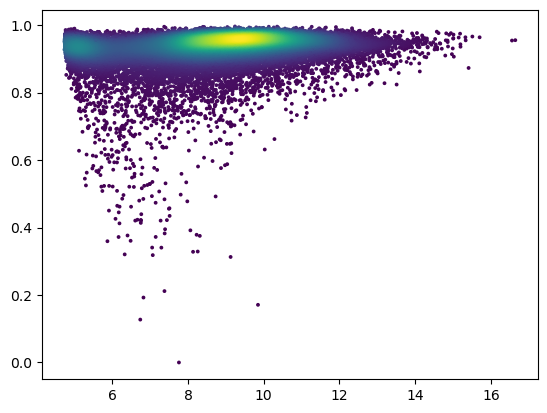

In [2]:
from scipy.stats import gaussian_kde

x = final_df['avgExpression']
y = final_df['stabilityIndex']

xy = np.vstack([x,y])
z = gaussian_kde(xy)(xy)

idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
ax.scatter(x,y,c=z, s=3)
plt.show()

In [3]:
N = 12
final_df["_bin_ae"] = pd.qcut(
    final_df['avgExpression'],
    q=N,
    labels=False
)
promoter_set_exp = (
    final_df
    .groupby("_bin_ae")
    .sample(n=1, random_state=42069)[['index','avgExpression','stabilityIndex']]
    .sort_values('avgExpression')
    .reset_index(drop=True)
)
final_df.drop(columns="_bin_ae", inplace=True)

final_df["_bin_si"] = pd.qcut(
    final_df['stabilityIndex'],
    q=N,
    labels=False
)
promoter_set_si = (
    final_df
    .groupby("_bin_si")
    .sample(n=1, random_state=691738)[['index','avgExpression','stabilityIndex']]
    .sort_values('stabilityIndex')
    .reset_index(drop=True)
)
final_df.drop(columns="_bin_si", inplace=True)

In [4]:
final_df['Score'] = final_df['avgExpression'] * final_df['stabilityIndex']

final_df["_bin_sc"] = pd.qcut(
    final_df['Score'],
    q=N,
    labels=False
)
promoter_set_score = (
    final_df
    .groupby("_bin_sc")
    .sample(n=1, random_state=6769699)[['index','Score','avgExpression','stabilityIndex']]
    .sort_values('Score')
    .reset_index(drop=True)
)

final_df.drop(columns='_bin_sc', inplace=True)
promoter_set_score.loc[12] = ['g13472', 15.901913517164713, 16.64114148907991, 0.9555782893619236]

I just thought of something. Carlos's stability index score only normalizes across the 12 genes I have selected, but my stability index is normalized against the entire genome.

In [5]:
#import braker files to search for protein sequence
input_fasta = "braker.faa.gz"
output_fasta = "promoter_genes_feb20.fa"

# Convert gene IDs to a set of strings for fast lookup
gene_ids = set(promoter_set_score['index'].astype(str))

with gzip.open(input_fasta, "rt") as handle, open(output_fasta, "w") as out:
    for record in SeqIO.parse(handle, "fasta"):
        # Remove .t1 or .t2 suffix from BRAKER IDs
        if record.id.endswith(".t1") and record.id.split(".")[0] in gene_ids:
            SeqIO.write(record, out, "fasta")

print(f"Done! Wrote protein sequences for {len(gene_ids)} genes.")

KeyboardInterrupt: 

In [ ]:
#import fasta files to search for nucleotide sequence
input_nuc = "assembly_cds.fasta"
output_nuc = "promoter_set_cds_feb20.fasta"

seen_genes = set()

with open(output_nuc, "w") as out_fh:
    for record in SeqIO.parse(input_nuc, "fasta"):
        # parse header fields
        fields = {
            f.split("=")[0]: f.split("=")[1]
            for f in record.id.split(";")
            if "=" in f
        }

        gene = fields.get("Parent")   # gene-level ID (e.g. g1)

        # keep only first isoform per gene
        if gene in gene_ids and gene not in seen_genes:
            SeqIO.write(record, out_fh, "fasta")
            seen_genes.add(gene)


In [ ]:
# Load BLAST results
cols = ["qseqid", "contig", "start", "end", "strand", "pident", "length"]
blast = pd.read_csv("cds_vs_genome.tsv", sep="\t", names=cols)

# Load genome into dictionary
genome = SeqIO.to_dict(SeqIO.parse("assembly.fasta", "fasta"))

PROMOTER_LEN = 1000
records = []

for _, row in blast.iterrows():
    gene = row.qseqid
    contig = row.contig
    start = int(row.start)
    end = int(row.end)
    strand = row.strand

    seq = genome[contig].seq

    if strand == "plus":
        prom_start = max(0, min(start, end) - PROMOTER_LEN - 1)
        prom_end = min(start, end) - 1
        promoter = seq[prom_start:prom_end]

    elif strand == "minus":
        prom_start = max(start, end)
        prom_end = min(len(seq), prom_start + PROMOTER_LEN)
        promoter = seq[prom_start:prom_end].reverse_complement()

    else:
        continue

    records.append(
        SeqIO.SeqRecord(
            promoter,
            id=f"{gene}_promoter",
            description=""
        )
    )

# Write promoter FASTA
SeqIO.write(records, "promoter_set_upstream_feb20.fasta", "fasta")

13

In [ ]:
string_mapping = pd.read_csv('string_mapping_feb_20.tsv', sep='\t',header=0)


ATCC11559V2 = {
    "g20183": "1925376",
    "g18882": "1899529",
    "g7124": "1795999",
    "g16051": "1798840",
    "g21791": "1916071",
    "g10325": "1922015",
    "g16856": "1903650",
    "g15486": "1062622",
    "g2522": "1888202",
    "g22818": "1924314",
    "g7144": "1822622",
    "g2780": "1356428",
    "g13472": "1894307"
}

promoter_set_score['ATCC11559_V2'] = promoter_set_score['index'].map(ATCC11559V2)

In [ ]:
promoter_set_score.to_excel("promoter_set_score.xlsx", index=False)

In [ ]:
final_df.to_excel("final_df.xlsx", index=False)

In [ ]:
filtered_map = pd.read_csv('/Users/wilsonporteus/Library/CloudStorage/OneDrive-ImperialCollegeLondon/Research documentation/Code/mmseq2 alignments/52813_dictionary.csv')

In [ ]:
# Filter filtered_map to only rows where 'query' ends in '.t1'
filtered_t1 = filtered_map[filtered_map['query'].str.endswith('.t1')]

# Extract the base id (e.g. 'g1.t1' -> 'g1') to match final_df's 'index' column
filtered_t1_ids = filtered_t1['query'].str.replace(r'\.t1$', '', regex=True)

# Keep only entries in final_df whose 'index' is in that set
af_df = final_df[final_df['index'].isin(filtered_t1_ids)]

In [ ]:
# Sort by score just to make this easier to reason about
sorted_df = af_df.sort_values('Score').reset_index(drop=False)
# (reset_index keeps your gene labels in a column called 'index')

# Define 12 evenly spaced percentiles from 0 to 100
percentiles = np.linspace(0, 100, 12)

# Find the actual score value at each percentile
target_scores = np.percentile(af_df['Score'], percentiles)

# For each target score, find the gene whose score is closest to it
selected_idx = []
used = set()

for target in target_scores:
    # closest remaining row by absolute distance to target score
    diffs = (sorted_df['Score'] - target).abs()
    diffs[sorted_df.index.isin(used)] = np.inf  # avoid picking the same gene twice
    idx = diffs.idxmin()
    selected_idx.append(idx)
    used.add(idx)

promoters_af = sorted_df.loc[selected_idx].sort_values('Score').reset_index(drop=True)
promoters_af = promoters_af[['index', 'Score']]

In [ ]:
# Create a gene-id column in filtered_map by stripping the transcript suffix
filtered_map = filtered_map.copy()
filtered_map['gene_id'] = filtered_map['query'].str.split('.').str[0]

# Merge on the gene_id <-> index match
promoters_af = promoters_af.merge(
    filtered_map[['gene_id', 'protein_id', 'uniprot_description']],
    left_on='index',
    right_on='gene_id',
    how='left'
)

# Drop the helper column now that the merge is done
promoters_af = promoters_af.drop(columns='gene_id')

In [ ]:
#import braker files to search for protein sequence
input_fasta = "braker.faa.gz"
output_fasta = "promoter_genes_july7.fa"

# Convert gene IDs to a set of strings for fast lookup
gene_ids = set(promoters_af['index'].astype(str))

with gzip.open(input_fasta, "rt") as handle, open(output_fasta, "w") as out:
    for record in SeqIO.parse(handle, "fasta"):
        # Remove .t1 or .t2 suffix from BRAKER IDs
        if record.id.endswith(".t1") and record.id.split(".")[0] in gene_ids:
            SeqIO.write(record, out, "fasta")

print(f"Done! Wrote protein sequences for {len(gene_ids)} genes.")

#import fasta files to search for nucleotide sequence
input_nuc = "assembly_cds.fasta"
output_nuc = "promoter_set_cds_july7.fasta"

seen_genes = set()

with open(output_nuc, "w") as out_fh:
    for record in SeqIO.parse(input_nuc, "fasta"):
        # parse header fields
        fields = {
            f.split("=")[0]: f.split("=")[1]
            for f in record.id.split(";")
            if "=" in f
        }

        gene = fields.get("Parent")   # gene-level ID (e.g. g1)

        # keep only first isoform per gene
        if gene in gene_ids and gene not in seen_genes:
            SeqIO.write(record, out_fh, "fasta")
            seen_genes.add(gene)